# Нейрон, градиенты и оптимизация весов

Обучим один нейрон восстанавливать зависимость `y = 2x + 0.5`. Сравним SGD и Adam по ошибке и полученным параметрам.


## Ход работы

Создаём 100 обучающих пар по зависимости `y = 2x + 0.5` и задаём модель из одного линейного слоя. Сначала вычисляем предсказания и MSE для случайных весов, затем обучаем модель с SGD в течение 100 эпох. В каждой эпохе очищаем градиенты, вычисляем ошибку, выполняем обратное распространение и обновляем параметры.

После обучения сравниваем вес и смещение с заданными значениями 2 и 0.5. Затем обучаем модель с Adam и строим кривую ошибки. По параметрам и графикам оцениваем, насколько близко каждый запуск подошёл к исходной зависимости.


### Импорты и фиксирование случайности

Подключаем PyTorch и Matplotlib. Фиксированное начальное состояние генераторов нужно, чтобы повторный запуск было легче сравнивать с первым; результаты Adam и SGD всё равно зависят от настройки оптимизаторов.

In [2]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)


### Создаём обучающие пары

Берём 100 чисел от −1 до 1 и вычисляем для каждого правильный ответ по закону `y = 2x + 0.5`. Никакая нейросеть пока не используется: это известная зависимость, которую предстоит восстановить.

In [3]:

# 1. Создаём обучающие данные
x = torch.linspace(-1, 1, 100).reshape(-1, 1)
y = 2 * x + 0.5


### Простейшая модель: один линейный слой

`nn.Linear(1, 1)` содержит два обучаемых параметра - коэффициент при `x` и смещение `b`. Сначала они заданы случайно, поэтому прогноз ещё не совпадает с целевой прямой.

In [4]:

# 2. Создаём модель
model = nn.Linear(1, 1)


### Как измеряем ошибку

`MSELoss` усредняет квадраты разностей предсказания и ответа. Чем ближе коэффициенты к 2 и 0.5, тем меньше ошибка на этих обучающих точках.

In [5]:

# 3. Выбираем функцию потерь
loss_fn = nn.MSELoss()


### Настраиваем SGD

Передаём оптимизатору `model.parameters()` и задаём `lr=0.1`. SGD обновляет веса в направлении, противоположном градиенту ошибки; величину шага регулирует `lr`.

In [6]:

# 4. Создаём оптимизатор
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1
)

history = []


### Обучаем модель 100 эпох

В каждой эпохе выполняются четыре действия: обнуление старых градиентов, прямой проход, `backward()` и `step()`. В этом опыте используется вся выборка сразу, поэтому одна эпоха включает один шаг оптимизатора.

In [7]:

# 5. Обучаем модель
for epoch in range(100):

    optimizer.zero_grad()

    prediction = model(x)

    loss = loss_fn(prediction, y)

    loss.backward()

    optimizer.step()

    history.append(loss.item())

    
    if epoch % 10 == 0:
        print(
         f"Эпоха: {epoch:3d} | "
         f"Loss: {loss.item():.6f} | "
         f"Вес: {model.weight.item():.4f} | "
         f"Bias: {model.bias.item():.4f}"
        )


Эпоха:   0 | Loss: 0.627972 | Вес: 0.8486 | Bias: 0.7640
Эпоха:  10 | Loss: 0.128142 | Вес: 1.4307 | Bias: 0.5283
Эпоха:  20 | Loss: 0.031032 | Вес: 1.7185 | Bias: 0.5030
Эпоха:  30 | Loss: 0.007582 | Вес: 1.8608 | Bias: 0.5003
Эпоха:  40 | Loss: 0.001854 | Вес: 1.9312 | Bias: 0.5000
Эпоха:  50 | Loss: 0.000453 | Вес: 1.9660 | Bias: 0.5000
Эпоха:  60 | Loss: 0.000111 | Вес: 1.9832 | Bias: 0.5000
Эпоха:  70 | Loss: 0.000027 | Вес: 1.9917 | Bias: 0.5000
Эпоха:  80 | Loss: 0.000007 | Вес: 1.9959 | Bias: 0.5000
Эпоха:  90 | Loss: 0.000002 | Вес: 1.9980 | Bias: 0.5000


### Что выучила модель

Выводим вес и смещение и сравниваем их с заданными значениями `w=2`, `b=0.5`.

In [8]:


# 6. Выводим результат
print("Вес:", model.weight.item())
print("Смещение:", model.bias.item())


Вес: 1.998921513557434
Смещение: 0.5000001192092896


### График обучения и отдельный опыт с Adam

На кривой MSE видно, как уменьшается ошибка. Сравнение с Adam стоит читать отдельно: у оптимизаторов различается способ вычисления шага, поэтому одинаковый `lr` не делает обучение эквивалентным.

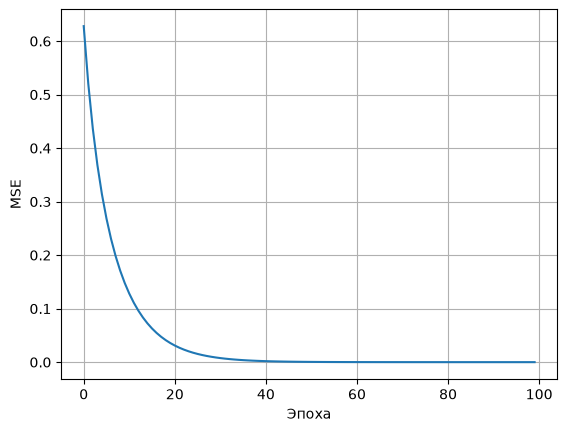

Обучение SGD завершён. Далее Adam с теми же начальными весами.
Adam: вес 2.0056369304656982 смещение 0.4997382164001465


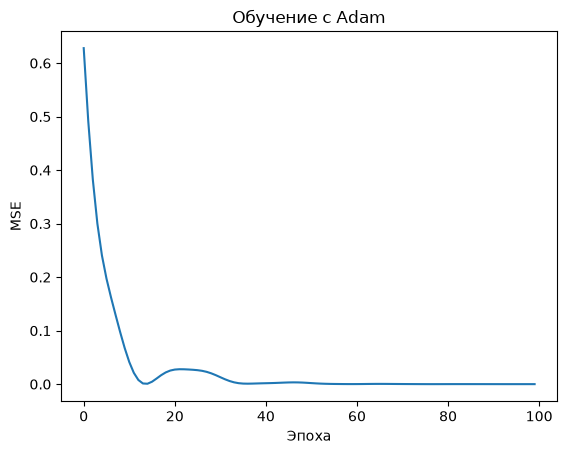

In [9]:

# 7. Строим график ошибки
plt.plot(history)
plt.xlabel("Эпоха")
plt.ylabel("MSE")
plt.grid()
plt.show()

print("Обучение SGD завершён. Далее Adam с теми же начальными весами.")
torch.manual_seed(42)
model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
history=[]
for epoch in range(100):
    optimizer.zero_grad()
    loss=loss_fn(model(x),y)
    loss.backward()
    optimizer.step()
    history.append(loss.item())
print("Adam: вес",model.weight.item(),"смещение",model.bias.item())
plt.plot(history); plt.title("Обучение с Adam"); plt.ylabel("MSE"); plt.xlabel("Эпоха"); plt.show()


## Выводы

Оба оптимизатора приближают вес к 2, а смещение к 0.5. По кривым MSE можно сравнить ход обучения при выбранном шаге `lr=0.1`.


## Полный код


In [ ]:
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1)
torch.manual_seed(42)
np.random.seed(42)

import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 1. Создаём обучающие данные
x = torch.linspace(-1, 1, 100).reshape(-1, 1)
y = 2 * x + 0.5

# 2. Создаём модель
model = nn.Linear(1, 1)

# 3. Выбираем функцию потерь
loss_fn = nn.MSELoss()

# 4. Создаём оптимизатор
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1
)

history = []

# 5. Обучаем модель
for epoch in range(100):

    optimizer.zero_grad()

    prediction = model(x)

    loss = loss_fn(prediction, y)

    loss.backward()

    optimizer.step()

    history.append(loss.item())

    
    if epoch % 10 == 0:
        print(
         f"Эпоха: {epoch:3d} | "
         f"Loss: {loss.item():.6f} | "
         f"Вес: {model.weight.item():.4f} | "
         f"Bias: {model.bias.item():.4f}"
        )


# 6. Выводим результат
print("Вес:", model.weight.item())
print("Смещение:", model.bias.item())

# 7. Строим график ошибки
plt.plot(history)
plt.xlabel("Эпоха")
plt.ylabel("MSE")
plt.grid()
plt.show()

print("Обучение SGD завершён. Далее Adam с теми же начальными весами.")
torch.manual_seed(42)
model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
history=[]
for epoch in range(100):
    optimizer.zero_grad()
    loss=loss_fn(model(x),y)
    loss.backward()
    optimizer.step()
    history.append(loss.item())
print("Adam: вес",model.weight.item(),"смещение",model.bias.item())
plt.plot(history); plt.title("Обучение с Adam"); plt.ylabel("MSE"); plt.xlabel("Эпоха"); plt.show()
